In [2]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


/home/lihaoxing/tmp/ipykernel_1857348/718535199.py:157: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_1857348/718535199.py:187: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_means = df.groupby("Phenotype")["CytoTRACE2_Score"].mean()


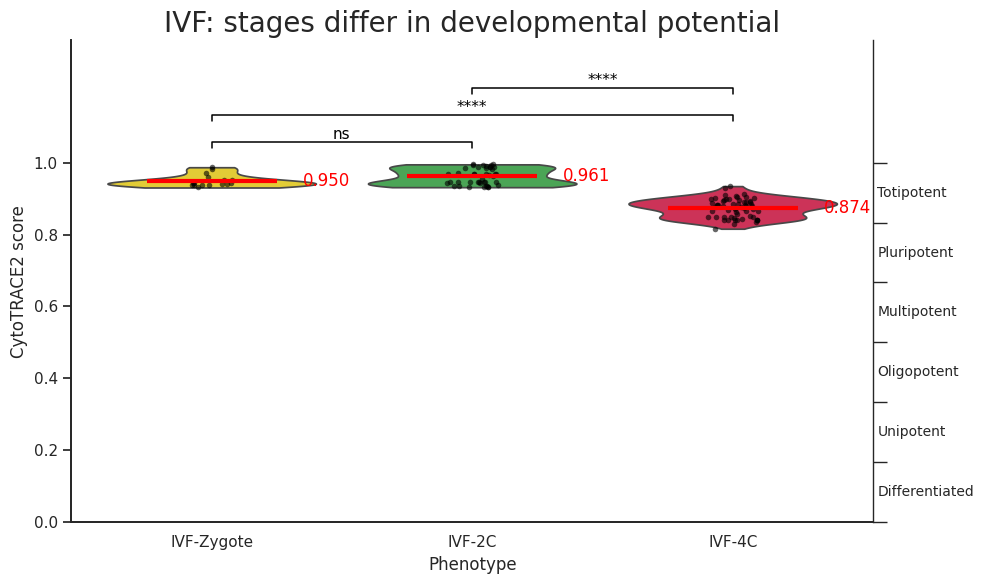

Sample sizes:
IVF-Zygote: n=16, median=0.9435
IVF-2C: n=42, median=0.9645
IVF-4C: n=60, median=0.8779

Kruskal-Wallis: H=87.6627, P=9.2104e-20

Pairwise Mann-Whitney U tests with BH correction:
IVF-Zygote vs IVF-2C: raw P=6.1456e-02, FDR=6.1456e-02, ns
IVF-Zygote vs IVF-4C: raw P=1.0831e-09, FDR=1.6247e-09, ****
IVF-2C vs IVF-4C: raw P=1.7473e-17, FDR=5.2418e-17, ****


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl                     
import seaborn as sns
from scipy.stats import kruskal, mannwhitneyu
from statsmodels.stats.multitest import multipletests
from itertools import combinations
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
plt.rcParams['axes.unicode_minus'] = False

sns.set(style="white")  # 去掉网格

# ============================================================
# Input / Output
# ============================================================

input_file = "/home/lihaoxing/jupyter/ct2results.txt"

# ============================================================
# Read data
# ============================================================

with open(input_file, "r", encoding="utf-8") as f:
    lines = [
        line.rstrip("\n\r")
        for line in f
        if line.strip()
    ]

header = [
    "CellID",
    "CytoTRACE2_Score",
    "CytoTRACE2_Potency",
    "CytoTRACE2_Relative",
    "UMAP1",
    "UMAP2",
    "Phenotype"
]

rows = []

for line in lines[1:]:
    fields = line.split("\t")
    if len(fields) == 7:
        rows.append(fields)

df = pd.DataFrame(
    rows,
    columns=header
)

# Convert CytoTRACE2 score to numeric
df["CytoTRACE2_Score"] = pd.to_numeric(
    df["CytoTRACE2_Score"],
    errors="coerce"
)

# ============================================================
# Phenotype order
# ============================================================

phenotype_order = [
    "IVF-Zygote",
    "IVF-2C",
    "IVF-4C"
]

df["Phenotype"] = pd.Categorical(
    df["Phenotype"],
    categories=phenotype_order,
    ordered=True
)

# Remove invalid values
df = df.dropna(
    subset=[
        "Phenotype",
        "CytoTRACE2_Score"
    ]
)

# ============================================================
# Extract groups
# ============================================================

groups = [
    df.loc[
        df["Phenotype"] == phenotype,
        "CytoTRACE2_Score"
    ].values
    for phenotype in phenotype_order
]

# ============================================================
# Statistics
# ============================================================

H, p_kw = kruskal(*groups)

pairwise = []
raw_p = []

for i, j in combinations(range(3), 2):
    U, p = mannwhitneyu(
        groups[i],
        groups[j],
        alternative="two-sided"
    )
    pairwise.append((i, j, U, p))
    raw_p.append(p)

_, p_adj, _, _ = multipletests(
    raw_p,
    method="fdr_bh"
)

def sig_label(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return "ns"

# ============================================================
# Figure — seaborn 风格的小提琴图
# ============================================================



fig, ax = plt.subplots(
    figsize=(10, 6)
)

# ------------------------------------------------------------
# 颜色映射
# ------------------------------------------------------------

phenotype_colors = {
    "IVF-Zygote": "#ffe119",
    "IVF-2C": "#3cb44b",
    "IVF-4C": "#e6194b"
}

# ------------------------------------------------------------
# 1. 小提琴图（无内部线，半透明）
# ------------------------------------------------------------

sns.violinplot(
    x='Phenotype',
    y='CytoTRACE2_Score',
    data=df,
    order=phenotype_order,
    palette=phenotype_colors,
    inner=None,
    cut=0,
    ax=ax
)

# ------------------------------------------------------------
# 2. 散点图
# ------------------------------------------------------------

sns.stripplot(
    x='Phenotype',
    y='CytoTRACE2_Score',
    data=df,
    order=phenotype_order,
    color='black',
    size=4,
    alpha=0.6,
    ax=ax
)

# ------------------------------------------------------------
# 3. 红色均值线 + 数值
# ------------------------------------------------------------

group_means = df.groupby("Phenotype")["CytoTRACE2_Score"].mean()
xpos = np.arange(len(phenotype_order))

for i, g in enumerate(phenotype_order):
    mean_val = group_means[g]

    ax.hlines(
        y=mean_val,
        xmin=i - 0.25,
        xmax=i + 0.25,
        color='red',
        linewidth=3,
        zorder=5
    )

    ax.text(
        i + 0.35,
        mean_val,
        f"{mean_val:.3f}",
        ha='left',
        va='center',
        fontsize=12,
        color='red'
    )

# ------------------------------------------------------------
# 4. 手动绘制显著性括号
# ------------------------------------------------------------

base = 1.04
step = 0.075
height = 0.018

for k, ((i, j, U, p_raw), p_corr) in enumerate(zip(pairwise, p_adj)):
    y = base + k * step
    x1 = i
    x2 = j

    ax.plot(
        [x1, x1, x2, x2],
        [y, y + height, y + height, y],
        color="black",
        linewidth=1.1,
        clip_on=False
    )

    ax.text(
        (x1 + x2) / 2,
        y + height,
        sig_label(p_corr),
        ha="center",
        va="bottom",
        fontsize=11,
        color="black",
        clip_on=False
    )

# ------------------------------------------------------------
# 5. 坐标轴与标签
# ------------------------------------------------------------

ax.set_ylim(0, 1.34)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_ylabel("CytoTRACE2 score", fontsize=12)

ax.set_xticks(xpos)
ax.set_xticklabels(phenotype_order, fontsize=11)
ax.set_xlabel("Phenotype", fontsize=12)
ax.set_title("IVF: stages differ in developmental potential", fontsize=20)

sns.despine(ax=ax, top=True, right=True)

# ------------------------------------------------------------
# 6. 右侧 Potency 轴
# ------------------------------------------------------------

ax2 = ax.twinx()
ax2.set_ylim(0, 1.34)

boundaries = np.linspace(0, 1, 7)
potency_labels = [
    "Differentiated",
    "Unipotent",
    "Oligopotent",
    "Multipotent",
    "Pluripotent",
    "Totipotent"
]
potency_centers = (boundaries[:-1] + boundaries[1:]) / 2

ax2.set_yticks(boundaries)
ax2.set_yticklabels([])
ax2.tick_params(
    axis="y",
    which="major",
    length=10,
    width=1.0,
    direction="out",
    pad=8
)

for y, label in zip(potency_centers, potency_labels):
    ax2.text(
        1.005,
        y,
        label,
        transform=ax2.get_yaxis_transform(),
        ha="left",
        va="center",
        fontsize=10
    )

ax2.spines["right"].set_visible(True)
ax2.spines["right"].set_linewidth(1.0)
ax2.spines["top"].set_visible(False)

# ------------------------------------------------------------
# 7. 保存与显示
# ------------------------------------------------------------

plt.tight_layout()

plt.savefig('IVF_3stages_CytoTRACE2_meanline.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# ============================================================
# Print statistics
# ============================================================

print("Sample sizes:")

for phenotype, values in zip(
    phenotype_order,
    groups
):
    print(
        f"{phenotype}: "
        f"n={len(values)}, "
        f"median={np.median(values):.4f}"
    )

print(
    f"\nKruskal-Wallis: "
    f"H={H:.4f}, "
    f"P={p_kw:.4e}"
)

print(
    "\nPairwise Mann-Whitney U tests "
    "with BH correction:"
)

for ((i, j, U, p_raw), p_corr) in zip(pairwise, p_adj):
    print(
        f"{phenotype_order[i]} vs "
        f"{phenotype_order[j]}: "
        f"raw P={p_raw:.4e}, "
        f"FDR={p_corr:.4e}, "
        f"{sig_label(p_corr)}"
    )



各亚群细胞数量：
  IVF-2C-iDEG1: 27 个细胞
  IVF-2C-iDEG2: 15 个细胞
  IVF-4C-iDEG1: 15 个细胞
  IVF-4C-iDEG2: 45 个细胞

其他亚群：
  PA-2C-iDEG1: 18 个细胞
  PA-2C-iDEG2: 6 个细胞
  PA-4C-iDEG1: 23 个细胞
  PA-4C-iDEG2: 16 个细胞


/home/lihaoxing/tmp/ipykernel_1857348/3587468095.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

IVF-2C-iDEG1 vs. IVF-2C-iDEG2: Mann-Whitney-Wilcoxon test two-sided, P_val:4.808e-04 U_stat=6.900e+01
IVF-4C-iDEG1 vs. IVF-4C-iDEG2: Mann-Whitney-Wilcoxon test two-sided, P_val:9.691e-09 U_stat=1.000e+00


/home/lihaoxing/tmp/ipykernel_1857348/3587468095.py:144: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(


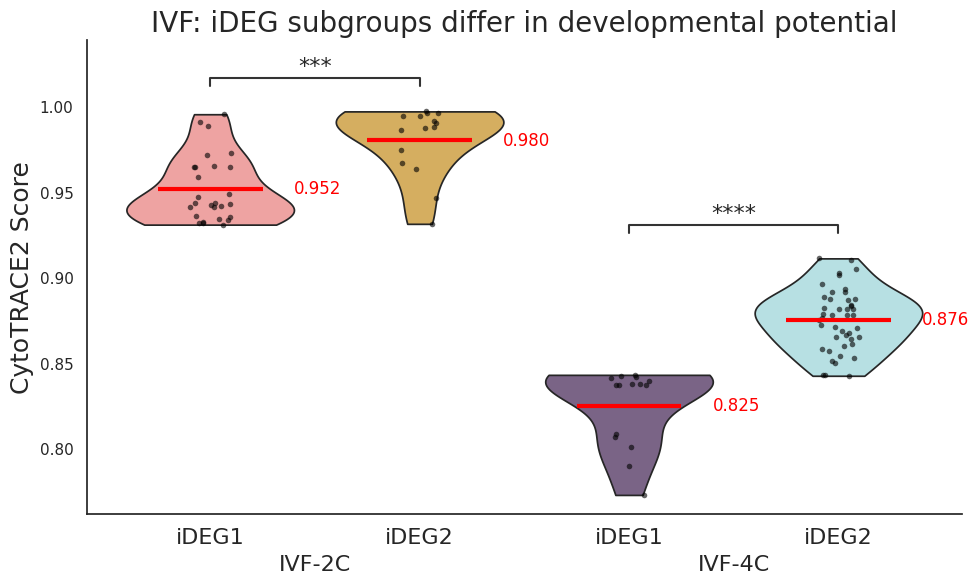

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False

sns.set(style="white")  # 去掉网格

# =========================
# data
# =========================
data = pd.read_csv('PA_IVF_198_CytoTRACE2_results_cluster2_dip.txt', sep='\t')

# =========================
# 打印各亚群细胞数量（按指定顺序）
# =========================
ordered = ["IVF-2C-iDEG1", "IVF-2C-iDEG2", "IVF-4C-iDEG1", "IVF-4C-iDEG2"]
print("\n各亚群细胞数量：")
for group in ordered:
    count = data[data['Phenotype2'] == group].shape[0]
    print(f"  {group}: {count} 个细胞")

# 如果存在未列出的亚群，也一并打印（可选）
all_groups = data['Phenotype2'].unique()
extra = [g for g in all_groups if g not in ordered]
if extra:
    print("\n其他亚群：")
    for g in extra:
        print(f"  {g}: {data[data['Phenotype2']==g].shape[0]} 个细胞")

# =========================
# original order（不改你的体系）
# =========================
# ordered 已定义

# =========================
# figure
# =========================
fig, ax = plt.subplots(figsize=(10, 6))

# =========================
# violin（❗保留原palette）
# =========================

# 颜色设置
color_mapping = {
    "PA-2C-iDEG1": "#7dace4",
    "PA-2C-iDEG2": "#ff165d",
    "PA-4C-iDEG1": "green",
    "PA-4C-iDEG2": "orange",
    "IVF-2C-iDEG1": "#fb9795", 
    "IVF-2C-iDEG2": "#E9B44C",
    "IVF-4C-iDEG1": "#7c5e8c",
    "IVF-4C-iDEG2": "#b0e7ea",
}

sns.violinplot(
    x='Phenotype2',
    y='CytoTRACE2_Score',
    data=data,
    order=ordered,
    palette=color_mapping,   # ⭐ 请确保 color_mapping 已定义
    inner=None,
    cut=0,
    ax=ax
)

# =========================
# scatter（黑色点不变）
# =========================
sns.stripplot(
    x='Phenotype2',
    y='CytoTRACE2_Score',
    data=data,
    order=ordered,
    color='black',
    size=4,
    alpha=0.6,
    ax=ax
)

# =========================
# mean line + value（红色）
# =========================
group_means = data.groupby("Phenotype2")["CytoTRACE2_Score"].mean()

for i, g in enumerate(ordered):
    mean_val = group_means[g]

    # 红色mean线
    ax.hlines(
        y=mean_val,
        xmin=i - 0.25,
        xmax=i + 0.25,
        color='red',
        linewidth=3,
        zorder=5
    )

    # mean数值
    ax.text(
        i + 0.4,          # ⭐ 向右偏移（关键）
        mean_val,
        f"{mean_val:.3f}",
        ha='left',         # ⭐ 左对齐（避免压线）
        va='center',
        fontsize=12,
        color='red'
    )

# =========================
# significance（图内）
# =========================
pairs = [
    ("IVF-2C-iDEG1", "IVF-2C-iDEG2"),
    ("IVF-4C-iDEG1", "IVF-4C-iDEG2")
]

annotator = Annotator(
    ax,
    pairs,
    data=data,
    x="Phenotype2",
    y="CytoTRACE2_Score",
    order=ordered
)

annotator.configure(
    test='Mann-Whitney',
    text_format='star',
    loc='inside',
    fontsize=16
)

annotator.apply_and_annotate()

# =========================
# x label（保留你的简化逻辑）
#=========================
ax.set_xticklabels(
    ["iDEG1", "iDEG2", "iDEG1", "iDEG2"],
    fontsize=16
)

# group label
ax.text(0.5, -0.12, "IVF-2C",
        transform=ax.get_xaxis_transform(),
        ha='center', fontsize=16)

ax.text(2.5, -0.12, "IVF-4C",
        transform=ax.get_xaxis_transform(),
        ha='center', fontsize=16)

# =========================
# style
# =========================
ax.set_ylabel("CytoTRACE2 Score", fontsize=18)
ax.set_xlabel("")
ax.set_title("IVF: iDEG subgroups differ in developmental potential", fontsize=20)

ax.grid(False)
sns.despine()

plt.tight_layout()
plt.savefig('IVF_CytoTRACE2_meanline.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

/home/lihaoxing/tmp/ipykernel_1857348/4134034010.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

IVF-2C-iDET1 vs. IVF-2C-iDET2: Mann-Whitney-Wilcoxon test two-sided, P_val:3.021e-03 U_stat=9.300e+01
IVF-4C-iDET1 vs. IVF-4C-iDET2: Mann-Whitney-Wilcoxon test two-sided, P_val:5.969e-06 U_stat=1.380e+02


/home/lihaoxing/tmp/ipykernel_1857348/4134034010.py:146: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(


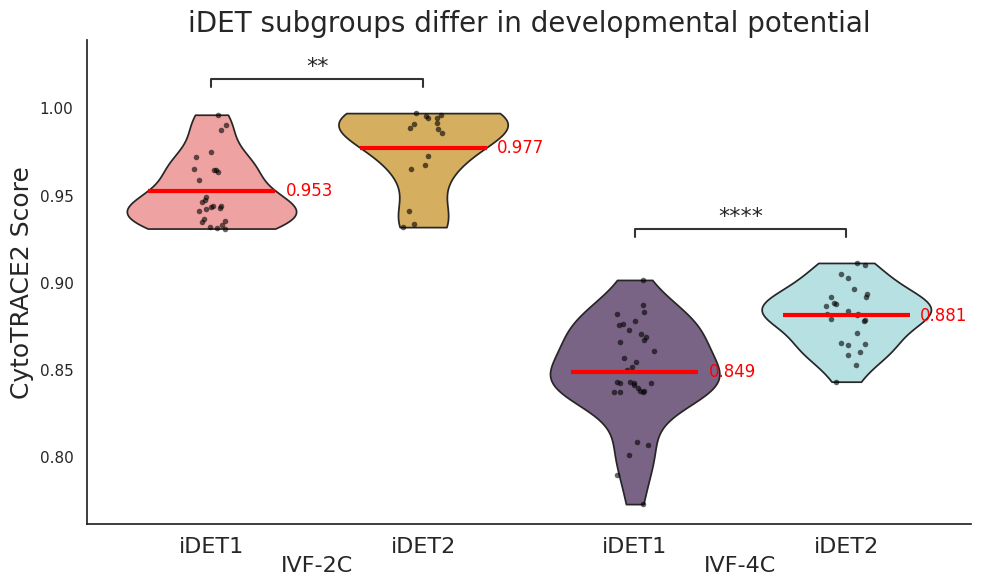

In [9]:


# 颜色设置
color_mapping = {
    "PA-2C-iDET1": "#7dace4",
    "PA-2C-iDET2": "#ff165d",
    "PA-4C-iDET1": "green",
    "PA-4C-iDET2": "orange",
    "IVF-2C-iDET1": "#fb9795", 
    "IVF-2C-iDET2": "#E9B44C",
    "IVF-4C-iDET1": "#7c5e8c",
    "IVF-4C-iDET2": "#b0e7ea",
}

# 横坐标标签替换
x_label_mapping = {
    "PA-2C-iDET1": "PA-2C-iDET1",
    "PA-2C-iDET2": "PA-2C-iDET2",
    "PA-4C-iDET1": "PA-4C-iDET1",
    "PA-4C-iDET2": "PA-4C-iDET2",
    "IVF-2C-iDET1": "IVF-2C-iDET1",
    "IVF-2C-iDET2": "IVF-2C-iDET2",
    "IVF-4C-iDET1": "IVF-4C-iDET1",
    "IVF-4C-iDET2": "IVF-4C-iDET2",
}

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
import numpy as np

# =========================
# style（和你最终版一致）
# =========================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False

sns.set(style="white")  # ❗统一：去grid

# =========================
# data
# =========================
data = pd.read_csv('PA_IVF_198_CytoTRACE2_results_cluster2_dip.txt', sep='\t')

# =========================
# order（iDET版本）
# =========================
ordered = [
    "IVF-2C-iDET1",
    "IVF-2C-iDET2",
    "IVF-4C-iDET1",
    "IVF-4C-iDET2"
]

# =========================
# figure
# =========================
fig, ax = plt.subplots(figsize=(10, 6))

# =========================
# violin（统一灰底 + palette保留）
# =========================
sns.violinplot(
    x='iDET-copy',
    y='CytoTRACE2_Score',
    data=data,
    order=ordered,
    palette=color_mapping,   # 保留原配色逻辑
    inner=None,
    cut=0,
    ax=ax
)

# =========================
# scatter（黑点）
# =========================
sns.stripplot(
    x='iDET-copy',
    y='CytoTRACE2_Score',
    data=data,
    order=ordered,
    color='black',
    size=4,
    alpha=0.6,
    ax=ax
)

# =========================
# mean line + value（统一风格）
# =========================
group_means = data.groupby("iDET-copy")["CytoTRACE2_Score"].mean()

for i, g in enumerate(ordered):
    mean_val = group_means[g]

    # red mean line
    ax.hlines(
        y=mean_val,
        xmin=i - 0.3,
        xmax=i + 0.3,
        color='red',
        linewidth=3,
        zorder=5
    )

    # mean value（右侧）
    ax.text(
        i + 0.35,
        mean_val,
        f"{mean_val:.3f}",
        ha='left',
        va='center',
        fontsize=12,
        color='red'
    )

# =========================
# significance（图内）
# =========================
pairs = [
    ("IVF-2C-iDET1", "IVF-2C-iDET2"),
    ("IVF-4C-iDET1", "IVF-4C-iDET2")
]

annotator = Annotator(
    ax,
    pairs,
    data=data,
    x="iDET-copy",
    y="CytoTRACE2_Score",
    order=ordered
)

annotator.configure(
    test='Mann-Whitney',
    text_format='star',
    loc='inside',
    fontsize=16
)

annotator.apply_and_annotate()

# =========================
# x labels（简化风格一致）
# =========================
ax.set_xticklabels(
    ["iDET1", "iDET2", "iDET1", "iDET2"],
    fontsize=16
)

# =========================
# group labels（保持统一结构）
# =========================
ax.text(0.5, -0.10, "IVF-2C",
        transform=ax.get_xaxis_transform(),
        ha='center', fontsize=16)

ax.text(2.5, -0.10, "IVF-4C",
        transform=ax.get_xaxis_transform(),
        ha='center', fontsize=16)

# =========================
# labels + title（统一风格）
# =========================
ax.set_ylabel("CytoTRACE2 Score", fontsize=18)
ax.set_xlabel("")
ax.set_title("iDET subgroups differ in developmental potential", fontsize=20)

# =========================
# clean style
# =========================
ax.grid(False)
sns.despine()

plt.tight_layout()
plt.savefig('IVF_CytoTRACE2_iDET_meanline.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

/home/lihaoxing/tmp/ipykernel_1857348/3074982436.py:157: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_1857348/3074982436.py:187: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_means = df.groupby("Phenotype")["CytoTRACE2_Score"].mean()


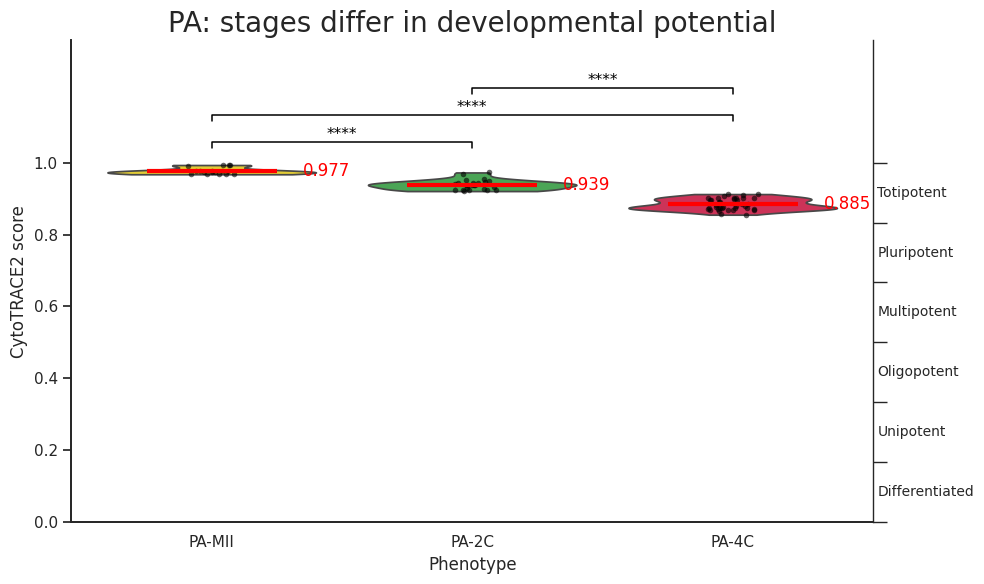

Sample sizes:
PA-MII: n=17, median=0.9756
PA-2C: n=24, median=0.9372
PA-4C: n=39, median=0.8819

Kruskal-Wallis: H=66.4443, P=3.7308e-15

Pairwise Mann-Whitney U tests with BH correction:
PA-MII vs PA-2C: raw P=1.9935e-07, FDR=1.9935e-07, ****
PA-MII vs PA-4C: raw P=3.6734e-09, FDR=5.5101e-09, ****
PA-2C vs PA-4C: raw P=3.6720e-11, FDR=1.1016e-10, ****


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl                     
import seaborn as sns
from scipy.stats import kruskal, mannwhitneyu
from statsmodels.stats.multitest import multipletests
from itertools import combinations
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
plt.rcParams['axes.unicode_minus'] = False

sns.set(style="white")  # 去掉网格

# ============================================================
# Input / Output
# ============================================================

input_file = "/home/lihaoxing/jupyter/PA_IVF_198_CytoTRACE2_results.txt"

# ============================================================
# Read data
# ============================================================

with open(input_file, "r", encoding="utf-8") as f:
    lines = [
        line.rstrip("\n\r")
        for line in f
        if line.strip()
    ]

header = [
    "ID",
    "CytoTRACE2_Score",
    "CytoTRACE2_Potency",
    "CytoTRACE2_Relative",
    "UMAP1",
    "UMAP2",
    "Phenotype"
]

rows = []

for line in lines[1:]:
    fields = line.split("\t")
    if len(fields) == 7:
        rows.append(fields)

df = pd.DataFrame(
    rows,
    columns=header
)

# Convert CytoTRACE2 score to numeric
df["CytoTRACE2_Score"] = pd.to_numeric(
    df["CytoTRACE2_Score"],
    errors="coerce"
)

# ============================================================
# Phenotype order
# ============================================================

phenotype_order = [
    "PA-MII",
    "PA-2C",
    "PA-4C"
]

df["Phenotype"] = pd.Categorical(
    df["Phenotype"],
    categories=phenotype_order,
    ordered=True
)

# Remove invalid values
df = df.dropna(
    subset=[
        "Phenotype",
        "CytoTRACE2_Score"
    ]
)

# ============================================================
# Extract groups
# ============================================================

groups = [
    df.loc[
        df["Phenotype"] == phenotype,
        "CytoTRACE2_Score"
    ].values
    for phenotype in phenotype_order
]

# ============================================================
# Statistics
# ============================================================

H, p_kw = kruskal(*groups)

pairwise = []
raw_p = []

for i, j in combinations(range(3), 2):
    U, p = mannwhitneyu(
        groups[i],
        groups[j],
        alternative="two-sided"
    )
    pairwise.append((i, j, U, p))
    raw_p.append(p)

_, p_adj, _, _ = multipletests(
    raw_p,
    method="fdr_bh"
)

def sig_label(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return "ns"

# ============================================================
# Figure — seaborn 风格的小提琴图
# ============================================================



fig, ax = plt.subplots(
    figsize=(10, 6)
)

# ------------------------------------------------------------
# 颜色映射
# ------------------------------------------------------------

phenotype_colors = {
    "PA-MII": "#ffe119",
    "PA-2C": "#3cb44b",
    "PA-4C": "#e6194b"
}

# ------------------------------------------------------------
# 1. 小提琴图（无内部线，半透明）
# ------------------------------------------------------------

sns.violinplot(
    x='Phenotype',
    y='CytoTRACE2_Score',
    data=df,
    order=phenotype_order,
    palette=phenotype_colors,
    inner=None,
    cut=0,
    ax=ax
)

# ------------------------------------------------------------
# 2. 散点图
# ------------------------------------------------------------

sns.stripplot(
    x='Phenotype',
    y='CytoTRACE2_Score',
    data=df,
    order=phenotype_order,
    color='black',
    size=4,
    alpha=0.6,
    ax=ax
)

# ------------------------------------------------------------
# 3. 红色均值线 + 数值
# ------------------------------------------------------------

group_means = df.groupby("Phenotype")["CytoTRACE2_Score"].mean()
xpos = np.arange(len(phenotype_order))

for i, g in enumerate(phenotype_order):
    mean_val = group_means[g]

    ax.hlines(
        y=mean_val,
        xmin=i - 0.25,
        xmax=i + 0.25,
        color='red',
        linewidth=3,
        zorder=5
    )

    ax.text(
        i + 0.35,
        mean_val,
        f"{mean_val:.3f}",
        ha='left',
        va='center',
        fontsize=12,
        color='red'
    )

# ------------------------------------------------------------
# 4. 手动绘制显著性括号
# ------------------------------------------------------------

base = 1.04
step = 0.075
height = 0.018

for k, ((i, j, U, p_raw), p_corr) in enumerate(zip(pairwise, p_adj)):
    y = base + k * step
    x1 = i
    x2 = j

    ax.plot(
        [x1, x1, x2, x2],
        [y, y + height, y + height, y],
        color="black",
        linewidth=1.1,
        clip_on=False
    )

    ax.text(
        (x1 + x2) / 2,
        y + height,
        sig_label(p_corr),
        ha="center",
        va="bottom",
        fontsize=11,
        color="black",
        clip_on=False
    )

# ------------------------------------------------------------
# 5. 坐标轴与标签
# ------------------------------------------------------------

ax.set_ylim(0, 1.34)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_ylabel("CytoTRACE2 score", fontsize=12)

ax.set_xticks(xpos)
ax.set_xticklabels(phenotype_order, fontsize=11)
ax.set_xlabel("Phenotype", fontsize=12)
ax.set_title("PA: stages differ in developmental potential", fontsize=20)

sns.despine(ax=ax, top=True, right=True)

# ------------------------------------------------------------
# 6. 右侧 Potency 轴
# ------------------------------------------------------------

ax2 = ax.twinx()
ax2.set_ylim(0, 1.34)

boundaries = np.linspace(0, 1, 7)
potency_labels = [
    "Differentiated",
    "Unipotent",
    "Oligopotent",
    "Multipotent",
    "Pluripotent",
    "Totipotent"
]
potency_centers = (boundaries[:-1] + boundaries[1:]) / 2

ax2.set_yticks(boundaries)
ax2.set_yticklabels([])
ax2.tick_params(
    axis="y",
    which="major",
    length=10,
    width=1.0,
    direction="out",
    pad=8
)

for y, label in zip(potency_centers, potency_labels):
    ax2.text(
        1.005,
        y,
        label,
        transform=ax2.get_yaxis_transform(),
        ha="left",
        va="center",
        fontsize=10
    )

ax2.spines["right"].set_visible(True)
ax2.spines["right"].set_linewidth(1.0)
ax2.spines["top"].set_visible(False)

# ------------------------------------------------------------
# 7. 保存与显示
# ------------------------------------------------------------

plt.tight_layout()

plt.savefig('PA_3stages_CytoTRACE2_meanline.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# ============================================================
# Print statistics
# ============================================================

print("Sample sizes:")

for phenotype, values in zip(
    phenotype_order,
    groups
):
    print(
        f"{phenotype}: "
        f"n={len(values)}, "
        f"median={np.median(values):.4f}"
    )

print(
    f"\nKruskal-Wallis: "
    f"H={H:.4f}, "
    f"P={p_kw:.4e}"
)

print(
    "\nPairwise Mann-Whitney U tests "
    "with BH correction:"
)

for ((i, j, U, p_raw), p_corr) in zip(pairwise, p_adj):
    print(
        f"{phenotype_order[i]} vs "
        f"{phenotype_order[j]}: "
        f"raw P={p_raw:.4e}, "
        f"FDR={p_corr:.4e}, "
        f"{sig_label(p_corr)}"
    )


/home/lihaoxing/tmp/ipykernel_436601/3814812694.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_436601/3814812694.py:58: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

PA-2C-A1 vs. PA-2C-A2: Mann-Whitney-Wilcoxon test two-sided, P_val:4.149e-01 U_stat=4.100e+01
PA-4C-B1 vs. PA-4C-B2: Mann-Whitney-Wilcoxon test two-sided, P_val:2.321e-02 U_stat=2.640e+02


/home/lihaoxing/tmp/ipykernel_436601/3814812694.py:106: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(new_labels, fontsize=16)


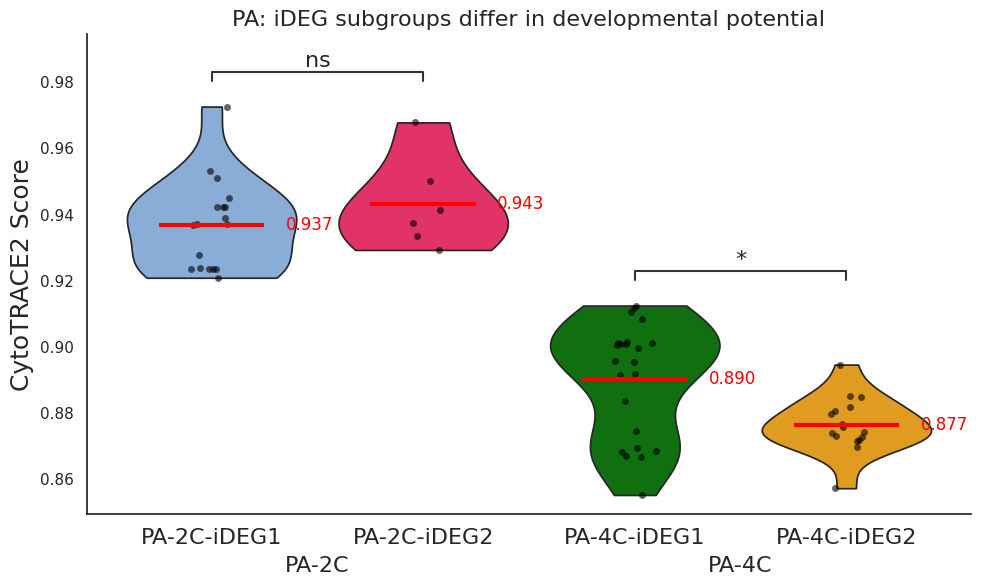

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
plt.rcParams['axes.unicode_minus'] = False

# =========================
# 读取数据
# =========================
data = pd.read_csv('PA_IVF_198_CytoTRACE2_results_cluster2_dip.txt', sep='\t')

# =========================
# 配色（保留原有）
# =========================
color_mapping = {
    "PA-2C-A1": "#7dace4",
    "PA-2C-A2": "#ff165d",
    "PA-4C-B1": "green",
    "PA-4C-B2": "orange",
    "IVF-2C-C1": "#A73BDD",
    "IVF-2C-C2": "#E7A31B",
    "IVF-4C-D1": "#2292A4",
    "IVF-4C-D2": "#E22720",
}

# =========================
# 横轴标签映射（保留原有）
# =========================
x_label_mapping = {
    "PA-2C-A1": "PA-2C-iDEG1",
    "PA-2C-A2": "PA-2C-iDEG2",
    "PA-4C-B1": "PA-4C-iDEG1",
    "PA-4C-B2": "PA-4C-iDEG2",
    "IVF-2C-C1": "IVF-2C-R1",
    "IVF-2C-C2": "IVF-2C-R2",
    "IVF-4C-D1": "IVF-4C-R1",
    "IVF-4C-D2": "IVF-4C-R2",
}

# =========================
# 只画 PA 轨迹（按原顺序）
# =========================
ordered_phenotypes = ["PA-2C-A1", "PA-2C-A2", "PA-4C-B1", "PA-4C-B2"]
new_labels = [x_label_mapping[label] for label in ordered_phenotypes]

# =========================
# 绘图
# =========================
sns.set(style="white")  # 无网格
fig, ax = plt.subplots(figsize=(10, 6))

# ---- 小提琴 ----
sns.violinplot(
    x='Phenotype2',
    y='CytoTRACE2_Score',
    data=data,
    order=ordered_phenotypes,
    palette=color_mapping,
    inner=None,          # 不画内部四分线（我们手动加散点）
    cut=0,
    scale="width",
    ax=ax
)

# ---- 黑色散点 ----
sns.stripplot(
    x='Phenotype2',
    y='CytoTRACE2_Score',
    data=data,
    order=ordered_phenotypes,
    color='black',
    size=5,
    alpha=0.6,
    ax=ax
)

# ---- 红色均值线 + 数值 ----
group_means = data.groupby("Phenotype2")["CytoTRACE2_Score"].mean()
for i, g in enumerate(ordered_phenotypes):
    mean_val = group_means[g]
    # 红色水平线（宽度 ±0.25）
    ax.hlines(y=mean_val, xmin=i-0.25, xmax=i+0.25,
              color='red', linewidth=3, zorder=5)
    # 数值显示在右侧（偏移 +0.3）
    ax.text(i + 0.35, mean_val, f"{mean_val:.3f}",
            ha='left', va='center', fontsize=12, color='red')

# ---- 统计检验（Mann-Whitney） ----
pairs = [("PA-2C-A1", "PA-2C-A2"),
         ("PA-4C-B1", "PA-4C-B2")]
annotator = Annotator(ax, pairs, data=data,
                      x="Phenotype2", y="CytoTRACE2_Score",
                      order=ordered_phenotypes)
annotator.configure(test='Mann-Whitney',
                    text_format='star',
                    loc='inside',      # 星号画在箱体内部
                    fontsize=16)
annotator.apply_and_annotate()

# ---- 横轴标签 ----
ax.set_xticklabels(new_labels, fontsize=16)
# 添加阶段分组标签（2C / 4C）
ax.text(0.5, -0.12, "PA-2C", transform=ax.get_xaxis_transform(),
        ha='center', fontsize=16)
ax.text(2.5, -0.12, "PA-4C", transform=ax.get_xaxis_transform(),
        ha='center', fontsize=16)

# ---- 坐标轴美化 ----
ax.set_ylabel("CytoTRACE2 Score", fontsize=18)
ax.set_xlabel("")
ax.set_title("PA: iDEG subgroups differ in developmental potential", fontsize=16)
sns.despine()          # 去掉上、右脊线
plt.tight_layout()

# ---- 保存 ----
plt.savefig('PA_CytoTRACE2_iDEG_meanline.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

/home/lihaoxing/tmp/ipykernel_436601/1648655104.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_436601/1648655104.py:57: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

PA-2C-iDET1 vs. PA-2C-iDET2: Mann-Whitney-Wilcoxon test two-sided, P_val:4.149e-01 U_stat=4.100e+01
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

PA-4C-iDET1 vs. PA-4C-iDET2: Mann-Whitney-Wilcoxon test two-sided, P_val:4.059e-01 U_stat=2.190e+02


/home/lihaoxing/tmp/ipykernel_436601/1648655104.py:107: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(new_labels, fontsize=16)


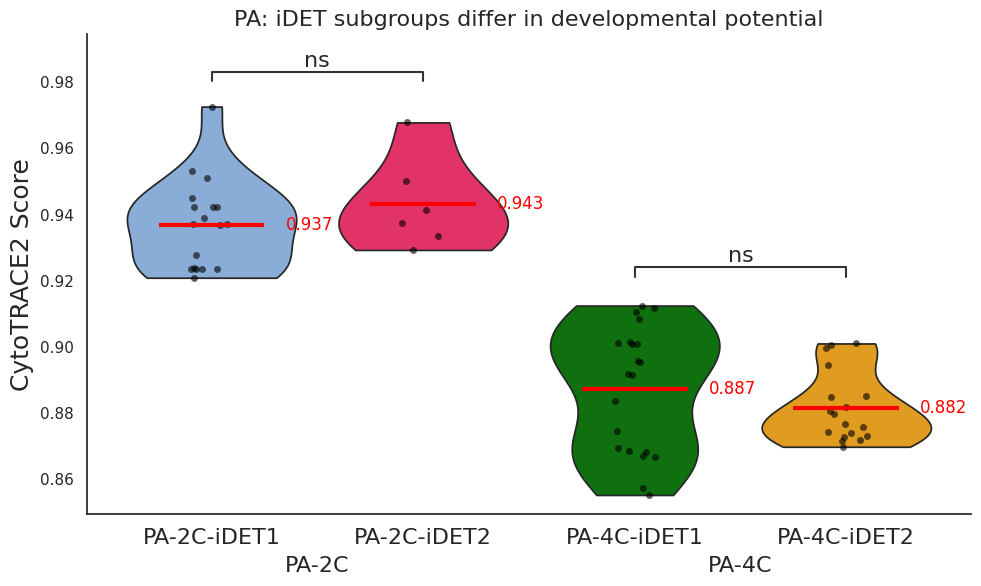

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
import numpy as np

# 字体设置
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 读取数据
data = pd.read_csv('PA_IVF_198_CytoTRACE2_results_cluster2_dip.txt', sep='\t')

# =========================
# 风格：白色背景，无网格
# =========================
sns.set(style="white")          # 关键：去掉网格
sns.set_context("notebook")     # 可选

# 颜色映射（完全保留）
color_mapping = {
    "PA-2C-iDET1": "#7dace4",
    "PA-2C-iDET2": "#ff165d",
    "PA-4C-iDET1": "green",
    "PA-4C-iDET2": "orange",
    "IVF-2C-iDET1": "#A73BDD",
    "IVF-2C-iDET2": "#E7A31B",
    "IVF-4C-iDET1": "#2292A4",
    "IVF-4C-iDET2": "#E22720",
}

# 横坐标标签（可根据需要修改，这里保持不变）
x_label_mapping = {
    "PA-2C-iDET1": "PA-2C-iDET1",
    "PA-2C-iDET2": "PA-2C-iDET2",
    "PA-4C-iDET1": "PA-4C-iDET1",
    "PA-4C-iDET2": "PA-4C-iDET2",
    "IVF-2C-iDET1": "IVF-2C-iDET1",
    "IVF-2C-iDET2": "IVF-2C-iDET2",
    "IVF-4C-iDET1": "IVF-4C-iDET1",
    "IVF-4C-iDET2": "IVF-4C-iDET2",
}

# 只画 PA 轨迹
ordered_phenotypes = ["PA-2C-iDET1", "PA-2C-iDET2", "PA-4C-iDET1", "PA-4C-iDET2"]
new_labels = [x_label_mapping[label] for label in ordered_phenotypes]

# =========================
# 绘图
# =========================
fig, ax = plt.subplots(figsize=(10, 6))

# ---- 小提琴（不带内部框线，只用外部形状） ----
sns.violinplot(
    x='iDET-copy',
    y='CytoTRACE2_Score',
    data=data,
    order=ordered_phenotypes,
    palette=color_mapping,
    inner=None,          # 不画内部四分线，由散点展示
    cut=0,
    scale="width",
    ax=ax
)

# ---- 黑色散点 ----
sns.stripplot(
    x='iDET-copy',
    y='CytoTRACE2_Score',
    data=data,
    order=ordered_phenotypes,
    color='black',
    size=5,
    alpha=0.6,
    ax=ax
)

# ---- 红色均值线 + 数值 ----
group_means = data.groupby("iDET-copy")["CytoTRACE2_Score"].mean()
for i, g in enumerate(ordered_phenotypes):
    mean_val = group_means[g]
    # 红色水平线（宽度 ±0.25）
    ax.hlines(y=mean_val, xmin=i-0.25, xmax=i+0.25,
              color='red', linewidth=3, zorder=5)
    # 数值显示在右侧（偏移 +0.3）
    ax.text(i + 0.35, mean_val, f"{mean_val:.3f}",
            ha='left', va='center', fontsize=12, color='red')

# ---- 统计检验（每对分别设置，并让星号显示在箱内） ----
pairs = [("PA-2C-iDET1", "PA-2C-iDET2"),
         ("PA-4C-iDET1", "PA-4C-iDET2")]

for pair in pairs:
    annotator = Annotator(ax, [pair], data=data,
                          x="iDET-copy", y="CytoTRACE2_Score",
                          order=ordered_phenotypes)
    annotator.configure(test='Mann-Whitney',
                        text_format='star',
                        loc='inside',      # 星号标在箱体内部
                        fontsize=16)
    annotator.apply_and_annotate()

# ---- 横轴标签 ----
ax.set_xticklabels(new_labels, fontsize=16)
# 添加阶段分组标签（2C / 4C）
ax.text(0.5, -0.12, "PA-2C", transform=ax.get_xaxis_transform(),
        ha='center', fontsize=16)
ax.text(2.5, -0.12, "PA-4C", transform=ax.get_xaxis_transform(),
        ha='center', fontsize=16)

# ---- 坐标轴美化 ----
ax.set_ylabel("CytoTRACE2 Score", fontsize=18)
ax.set_xlabel("")
ax.set_title("PA: iDET subgroups differ in developmental potential", fontsize=16)
sns.despine()          # 去掉上、右脊线
plt.tight_layout()

# ---- 保存 ----
plt.savefig('PA_CytoTRACE2_iDET-copy_meanline.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()